# Fair-Price Estimation for Used Cars in Sri Lanka

**Problem.** Used-car prices in Sri Lanka move fast. The vehicle-import suspension (2020–2024), the rupee
crisis and the 2025 reopening of imports made asking prices on classified sites hard to judge. Buyers and
sellers have no neutral reference for whether an asking price is fair.

**Goal.** Predict the market asking price (Rs.) of a used car from the details in a listing, so a user
can check whether a price is fair and see *why* the model values the car the way it does.

**Type.** Supervised regression on tabular data.

**Data.** About 6,400 real listings scraped from **riyasewana.com** (May–Aug 2026), covering 11 brands and
30 popular models. They come from the public MIT-licensed repository
[savindu777/Sri-Lanka-Car-Market-Anlaysis-2026](https://github.com/savindu777/Sri-Lanka-Car-Market-Anlaysis-2026)
(raw `dataset/` files only). All cleaning, feature engineering, modelling and explanation here are my own.

**Pipeline.** Data understanding → cleaning → feature engineering → EDA → leakage-safe preprocessing →
baselines → tuned ensembles (RF, XGBoost, LightGBM, CatBoost, stacking) → comparison → SHAP and LIME
explanations → what-if analysis → inference on unseen listings → saved model for the Streamlit app.

In [1]:
import glob, re, time, warnings, json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV, GridSearchCV, cross_validate
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
import shap
from lime.lime_tabular import LimeTabularExplainer

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
REF_YEAR = 2026
TUNE = True  # False reuses the saved best params
os.makedirs("figures", exist_ok=True); os.makedirs("models", exist_ok=True)

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
                     "axes.titlesize": 11, "font.size": 9.5})
def savefig(name):
    plt.tight_layout(); plt.savefig(f"figures/{name}.png", dpi=160, bbox_inches="tight"); plt.show()
print("Libraries loaded. shap", shap.__version__)

Libraries loaded. shap 0.54.1


/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load the raw listings
Each raw file is one search on riyasewana.com: a single model (e.g. *Toyota Aqua*) or a whole brand
(e.g. *Audi*). I keep the source file name because it tells us the model reliably. The free-text
`Model` column written by sellers is messy (e.g. "A1 Highest Spec", "Lancer Box").

In [2]:
frames = []
for f in sorted(glob.glob("data/raw/riyasewana_*.csv")):
    d = pd.read_csv(f)
    d["source"] = os.path.basename(f).replace("riyasewana_", "").replace(".csv", "")
    frames.append(d)
raw = pd.concat(frames, ignore_index=True)
print(f"{len(frames)} files, {raw.shape[0]:,} listings, {raw.shape[1]} columns")
raw.head(3)

30 files, 6,436 listings, 22 columns


,Brand,Model,YOM,Mileage,Gear,Fuel Type,Engine (cc),Condition,Ad Date,Location,...,Body Type,Number of Cylinders,Power Steering,Power Shutters,Power Mirrors,Manufacturing Country,source,Number of Cylinder,Power Shutter,Power Mirror
0,Audi,A3 Sline,2018,"93,000 km",Automatic,Petrol,1000.0,Registered (Used),"2026 Jun 05, 11:39 am",Colombo,...,Sedan,3.0,Yes,Yes,Yes,Germany,audi_edited,NaN,NaN,NaN
1,Audi,A1 Sline,2017,"96,000 km",Automatic,Petrol,990.0,Registered (Used),"2026 Jun 06, 10:27 pm",Kandy,...,Hatchback,3.0,Yes,Yes,Yes,Germany,audi_edited,NaN,NaN,NaN
2,Audi,A1 Highest Spec,2016,"86,000 km",Automatic,Petrol,10000.0,Registered (Used),"2026 Jul 19, 9:58 am",Colombo,...,Hatchback,6.0,Yes,Yes,Yes,Germany,audi_edited,NaN,NaN,NaN


In [3]:
summary = pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": raw.isna().sum(),
                        "unique": raw.nunique(), "example": raw.iloc[0]})
summary

,dtype,missing,unique,example
Brand,str,0,11,Audi
Model,str,0,1248,A3 Sline
YOM,int64,0,54,2018
Mileage,str,18,1504,"93,000 km"
Gear,str,0,2,Automatic
Fuel Type,str,0,4,Petrol
Engine (cc),float64,178,193,1000.0
Condition,str,0,4,Registered (Used)
Ad Date,str,0,5710,"2026 Jun 05, 11:39 am"
Location,str,0,110,Colombo


**First observations**
* `Price` is text ("Rs. 14400000"), and **1,440 ads (22%) say "Negotiable"** with no price. They cannot be
  used to train a price model.
* `Mileage` is text ("93,000 km").
* `Engine (cc)` has impossible values (1 cc, 10,000 cc, 149,000 cc), which are typing errors.
* Some brand files have different column spellings (`Power Shutter` vs `Power Shutters`).
* `Location` holds 110 towns. I map these to 24 of the 25 districts using local knowledge (no ads came from Mullaitivu).

## 2. Cleaning and feature engineering

In [4]:
def parse_number(s):
    if pd.isna(s): return np.nan
    digits = re.sub(r"[^\d]", "", str(s))
    return float(digits) if digits else np.nan

df = raw.copy()
for a, b in [("Power Shutters", "Power Shutter"), ("Power Mirrors", "Power Mirror"),
             ("Number of Cylinders", "Number of Cylinder")]:
    df[a] = df[a].fillna(df[b]); df.drop(columns=b, inplace=True)

df["price"] = df["Price"].apply(parse_number)
df["mileage_km"] = df["Mileage"].apply(parse_number)
df["ad_date"] = pd.to_datetime(df["Ad Date"].str.split(",").str[0], format="%Y %b %d", errors="coerce")
print("Ads without a price (Negotiable):", df["price"].isna().sum())

Ads without a price (Negotiable): 1440


In [5]:
# model family
FILE_MODEL = {"honda_city_edited": "City", "honda_civic_with_country": "Civic", "honda_cr-v_edited": "CR-V",
    "honda_fit_with_country": "Fit", "honda_grace_edited_cleaned": "Grace", "honda_vezel_edited": "Vezel",
    "nissan_clipper_with_country": "Clipper", "nissan_sunny_with_country": "Sunny",
    "suzuki_every_with_country": "Every", "suzuki_fronx_with_country": "Fronx", "suzuki_swift_with_country": "Swift",
    "suzuki_wagon_r_with_country": "Wagon R", "toyota_allion_with_country": "Allion", "toyota_aqua_with_country": "Aqua",
    "toyota_chr_with_country": "C-HR", "toyota_corolla_with_country": "Corolla", "toyota_premio_with_country": "Premio",
    "toyota_prius_with_country": "Prius", "toyota_raize": "Raize", "toyota_starlet_with_country": "Starlet",
    "toyota_vitz_edited_cleaned": "Vitz", "toyota_yaris": "Yaris",
    "volvo_edited_cleaned": "Volvo (all)", "jaguar_edited": "Jaguar (all)"}

def family_from_text(source, text):
    t = str(text).lower().strip()
    first = t.split()[0] if t else ""
    if source.startswith("audi"):
        m = re.match(r"(a[1-8])", first);            return m.group(1).upper() if m else None
    if source.startswith("bmw"):
        if first.startswith("i8"):                    return "i8"
        m = re.match(r"([1-7])\d", first);           return f"{m.group(1)} Series" if m else None
    if source.startswith("mercedes"):
        if first.startswith("cla"):                   return "CLA"
        if first.startswith("w210"):                  return "E-Class"
        m = re.match(r"([ces])\d", first);           return f"{m.group(1).upper()}-Class" if m else None
    if source.startswith("mazda"):
        return {"familia": "Familia", "demio": "Demio", "2": "Demio", "axela": "Axela", "3": "Axela",
                "6": "Atenza", "atenza": "Atenza", "323": "323", "flair": "Flair", "rx-8": "RX-8"}.get(first)
    if source.startswith("mitsubishi"):
        return {"lancer": "Lancer", "ek": "eK", "galant": "Galant", "attrage": "Attrage", "mirage": "Mirage",
                "minica": "Minica"}.get(first)
    if source.startswith("nissan_cleaned"):
        return {"march": "March", "dayz": "Dayz", "roox": "Dayz", "bluebird": "Bluebird", "pulsar": "Pulsar",
                "tiida": "Tiida", "cefiro": "Cefiro"}.get(first)
    return None

df["model_family"] = [FILE_MODEL.get(s) or family_from_text(s, m) for s, m in zip(df["source"], df["Model"])]
df["model_family"] = df["model_family"].fillna(df["Brand"] + " other")

In [6]:
# town -> district
TOWN_DISTRICT = {
 "Colombo":"Colombo","Avissawella":"Colombo","Battaramulla":"Colombo","Boralesgamuwa":"Colombo","Dehiwala-Mount-Lavinia":"Colombo",
 "Hanwella":"Colombo","Homagama":"Colombo","Kaduwela":"Colombo","Kesbewa":"Colombo","Kolonnawa":"Colombo","Kotikawatta":"Colombo",
 "Kottawa":"Colombo","Kotte":"Colombo","Maharagama":"Colombo","Malabe":"Colombo","Moratuwa":"Colombo","Mulleriyawa":"Colombo",
 "Nawala":"Colombo","Nugegoda":"Colombo","Padukka":"Colombo","Pannipitiya":"Colombo","Piliyandala":"Colombo","Rajagiriya":"Colombo","Peliyagoda":"Gampaha","Harispattuwa":"Kandy",
 "Gampaha":"Gampaha","Daluguma":"Gampaha","Divulapitiya":"Gampaha","Dompe":"Gampaha","Ganemulla":"Gampaha","Ja-Ela":"Gampaha",
 "Kadawatha":"Gampaha","Kandana":"Gampaha","Katunayake":"Gampaha","Kelaniya":"Gampaha","Kiribathgoda":"Gampaha","Minuwangoda":"Gampaha",
 "Mirigama":"Gampaha","Negombo":"Gampaha","Nittambuwa":"Gampaha","Ragama":"Gampaha","Veyangoda":"Gampaha","Wattala":"Gampaha","Welisara":"Gampaha",
 "Kalutara":"Kalutara","Bandaragama":"Kalutara","Beruwala":"Kalutara","Horana":"Kalutara","horana":"Kalutara","Matugama":"Kalutara","Panadura":"Kalutara",
 "Kandy":"Kandy","Gampola":"Kandy","Kadugannawa":"Kandy","Nawalapitiya":"Kandy","Wattegama":"Kandy",
 "Matale":"Matale","Dambulla":"Matale","Nuwara-Eliya":"Nuwara Eliya","Hatton":"Nuwara Eliya",
 "Galle":"Galle","Ambalangoda":"Galle","Bentota":"Galle","Elpitiya":"Galle","Hikkaduwa":"Galle","Koggala":"Galle",
 "Matara":"Matara","Weligama":"Matara","Hambantota":"Hambantota","Tangalle":"Hambantota","Middeniya":"Hambantota",
 "Kurunegala":"Kurunegala","Ambanpola":"Kurunegala","Kuliyapitiya":"Kurunegala","Pannala":"Kurunegala","Polgahawela":"Kurunegala",
 "Puttalam":"Puttalam","Chilaw":"Puttalam","Dankotuwa":"Puttalam","Marawila":"Puttalam","Nattandiya":"Puttalam","Wennappuwa":"Puttalam",
 "Anuradapura":"Anuradhapura","Polonnaruwa":"Polonnaruwa","Badulla":"Badulla","Bandarawela":"Badulla","Haputale":"Badulla",
 "Mahiyanganaya":"Badulla","Welimada":"Badulla","Moneragala":"Monaragala","Kataragama":"Monaragala",
 "Ratnapura":"Ratnapura","Balangoda":"Ratnapura","Eheliyagoda":"Ratnapura","Embilipitiya":"Ratnapura",
 "Kegalle":"Kegalle","Dehiowita":"Kegalle","Mawanella":"Kegalle","Ruwanwella":"Kegalle","Warakapola":"Kegalle",
 "Jaffna":"Jaffna","Kilinochchi":"Kilinochchi","Mannar":"Mannar","Vavuniya":"Vavuniya",
 "Batticaloa":"Batticaloa","Eravur":"Batticaloa","Ampara":"Ampara","Kalmunai":"Ampara","Sammanthurai":"Ampara","Trincomalee":"Trincomalee"}
df["district"] = df["Location"].map(TOWN_DISTRICT)
print("Unmapped towns:", df.loc[df["district"].isna(), "Location"].unique())

Unmapped towns: <ArrowStringArray>
[]
Length: 0, dtype: str


In [7]:
# numeric fields and engineered features
df["year"] = df["YOM"]
df["age"] = (REF_YEAR - df["year"]).clip(lower=0)
df["engine_cc"] = df["Engine (cc)"].where(df["Engine (cc)"].between(600, 6000))
df.loc[df["Condition"].eq("Brand New") & df["mileage_km"].isna(), "mileage_km"] = 0
df["mileage_km"] = df["mileage_km"].where(df["mileage_km"] <= 800_000)
df["km_per_year"] = df["mileage_km"] / df["age"].clip(lower=1)
power_cols = ["Power Steering", "Power Shutters", "Power Mirrors"]
df["power_options"] = df[power_cols].eq("Yes").sum(axis=1).where(df["Power Shutters"].notna())
df["origin_country"] = df["Manufacturing Country"].where(
    df["Manufacturing Country"].isin(["Japan", "Germany", "Thailand", "India"]), "Other")
df = df.rename(columns={"Brand": "brand", "Gear": "gear", "Fuel Type": "fuel_type",
                        "Condition": "condition", "Body Type": "body_type"})

print("engine_cc set to missing:", int(df["Engine (cc)"].notna().sum() - df["engine_cc"].notna().sum()))

engine_cc set to missing: 85


In [8]:
# row filters
log = [("Raw listings", len(df))]
df = df[df["price"].notna()];                                   log.append(("Drop 'Negotiable' (no price)", len(df)))
df = df[df["condition"] != "Antique"];                         log.append(("Drop 'Antique' (different market, 8 ads)", len(df)))
df = df[df["price"].between(300_000, 100_000_000)];             log.append(("Drop impossible prices (<Rs 0.3M or >Rs 100M)", len(df)))
dup_key = ["brand", "Model", "year", "mileage_km", "price", "Location"]
df = df.drop_duplicates(subset=dup_key);                        log.append(("Drop re-posted duplicate ads", len(df)))
fam_counts = df["model_family"].value_counts()
rare = fam_counts[fam_counts < 15].index
df.loc[df["model_family"].isin(rare), "model_family"] = df["brand"] + " other"
pd.DataFrame(log, columns=["Step", "Rows remaining"])

,Step,Rows remaining
0,Raw listings,6436
1,Drop 'Negotiable' (no price),4996
2,"Drop 'Antique' (different market, 8 ads)",4990
3,Drop impossible prices (<Rs 0.3M or >Rs 100M),4986
4,Drop re-posted duplicate ads,4912


Two decisions matter here:
* **Re-posted duplicates.** Sellers re-post the same car. If one copy lands in training and another in
  testing, the model gets an unfairly easy test. That is a form of data leakage, so I remove exact repeats
  of brand, model text, year, mileage, price and town.
* **Rare model families** (fewer than 15 ads) are grouped into "<Brand> other", so the model never learns
  from one or two examples.

In [9]:
CAT = ["brand", "model_family", "gear", "fuel_type", "condition", "body_type", "origin_country", "district"]
NUM = ["age", "mileage_km", "km_per_year", "engine_cc", "power_options"]
FEATURES = CAT + NUM
data = df[FEATURES + ["price", "year", "ad_date", "Model", "Location", "URL"]].reset_index(drop=True)
data[CAT] = data[CAT].astype(str)
print(data.shape)
data[FEATURES].describe(include="all").T[["count", "unique", "top", "mean", "50%", "min", "max"]]

(4912, 19)


,count,unique,top,mean,50%,min,max
brand,4912,11,Toyota,NaN,NaN,NaN,NaN
model_family,4912,49,Vitz,NaN,NaN,NaN,NaN
gear,4912,2,Automatic,NaN,NaN,NaN,NaN
fuel_type,4912,4,Petrol,NaN,NaN,NaN,NaN
condition,4912,3,Registered (Used),NaN,NaN,NaN,NaN
body_type,4912,4,Sedan,NaN,NaN,NaN,NaN
origin_country,4912,5,Japan,NaN,NaN,NaN,NaN
district,4912,24,Colombo,NaN,NaN,NaN,NaN
age,4912.0,NaN,NaN,14.102402,12.0,0.0,53.0
mileage_km,4909.0,NaN,NaN,119520.031167,123000.0,0.0,580000.0


## 3. Exploratory data analysis

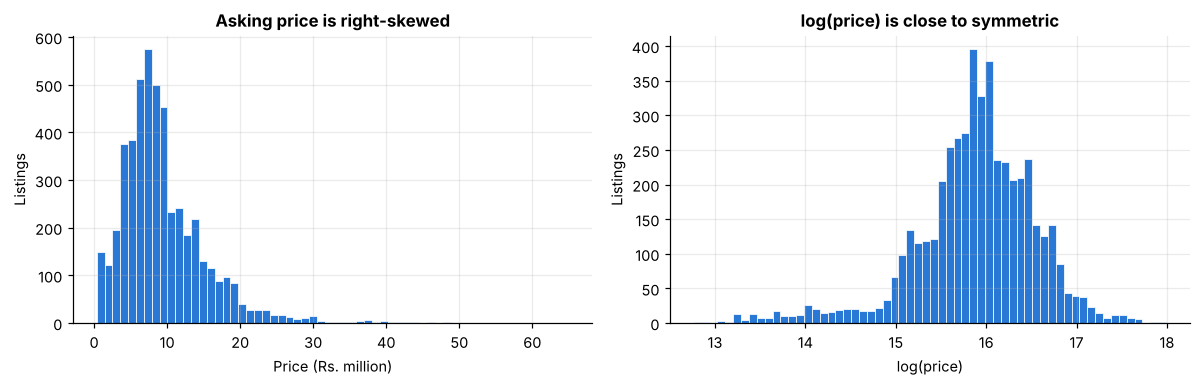

count         4,912
mean      9,513,117
std       6,082,466
min         350,000
25%       5,750,000
50%       8,237,500
75%      11,956,250
max      65,000,000
Name: price, dtype: str


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(data["price"] / 1e6, bins=60, color=BLUE, edgecolor="white", linewidth=0.5)
ax[0].set(title="Asking price is right-skewed", xlabel="Price (Rs. million)", ylabel="Listings")
ax[1].hist(np.log(data["price"]), bins=60, color=BLUE, edgecolor="white", linewidth=0.5)
ax[1].set(title="log(price) is close to symmetric", xlabel="log(price)", ylabel="Listings")
savefig("01_price_distribution")
print(data["price"].describe().apply(lambda v: f"{v:,.0f}"))

Prices run from about Rs 0.4M to Rs 65M with a long right tail (luxury German cars). I model
**log(price)**. Errors then become relative ("10% too high") rather than absolute, which suits a
market spanning a Rs 1M Alto-class car and a Rs 40M BMW. Predictions are converted back to rupees for
evaluation.

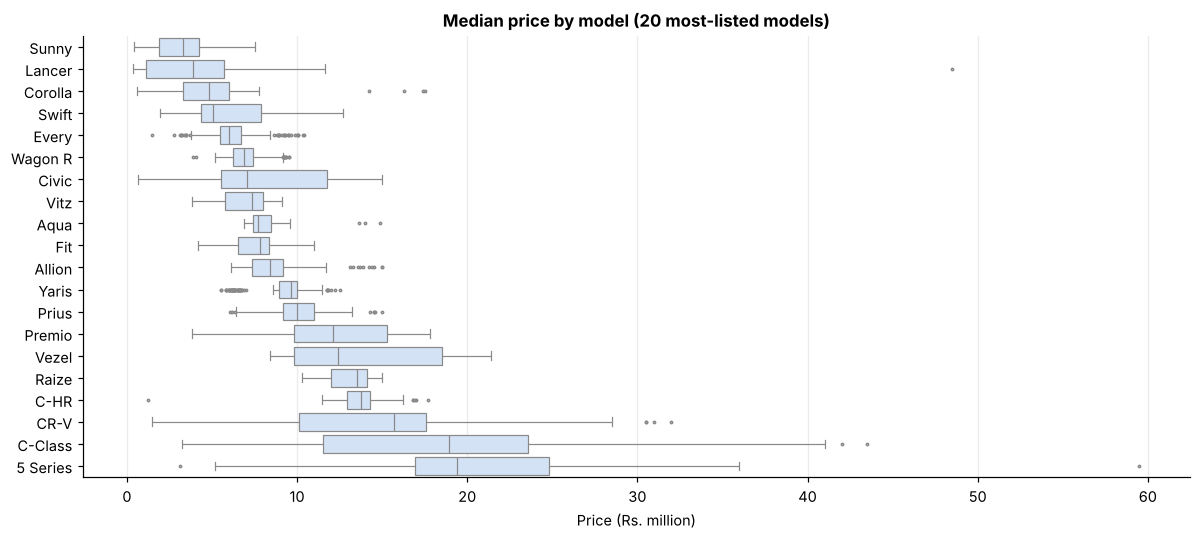

In [11]:
order = data.groupby("model_family")["price"].median().sort_values().index
top = data["model_family"].value_counts().head(20).index
sub = data[data["model_family"].isin(top)]
order = [m for m in order if m in top]
fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=sub, y="model_family", x=sub["price"] / 1e6, order=order, color="#cde2fb",
            fliersize=1.5, linewidth=0.8, ax=ax)
ax.set(title="Median price by model (20 most-listed models)", xlabel="Price (Rs. million)", ylabel="")
savefig("02_price_by_model")

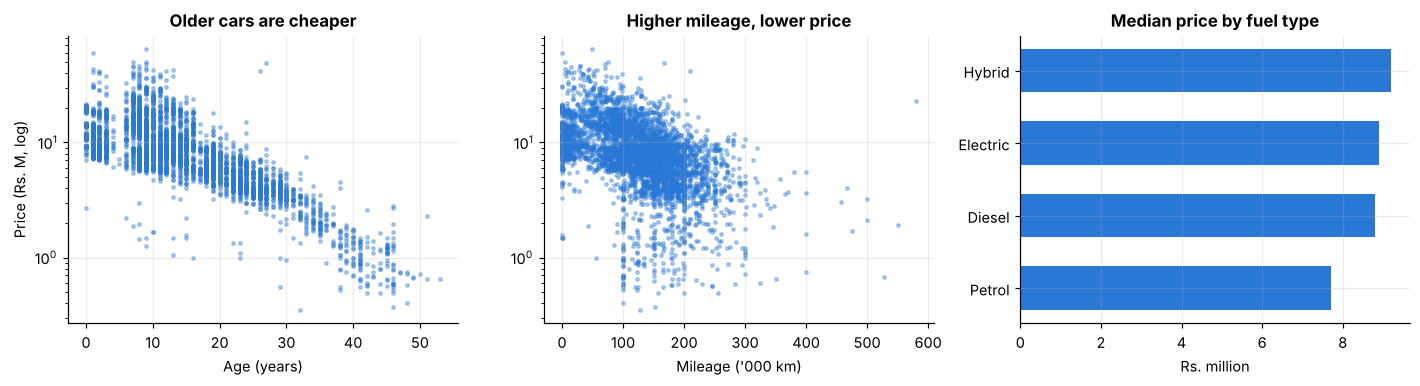

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].scatter(data["age"], data["price"] / 1e6, s=5, alpha=0.35, color=BLUE)
ax[0].set(yscale="log", title="Older cars are cheaper", xlabel="Age (years)", ylabel="Price (Rs. M, log)")
ax[1].scatter(data["mileage_km"] / 1000, data["price"] / 1e6, s=5, alpha=0.35, color=BLUE)
ax[1].set(yscale="log", title="Higher mileage, lower price", xlabel="Mileage ('000 km)")
fuel_med = data.groupby("fuel_type")["price"].median().sort_values() / 1e6
ax[2].barh(fuel_med.index, fuel_med.values, color=BLUE, height=0.6)
ax[2].set(title="Median price by fuel type", xlabel="Rs. million")
savefig("03_age_mileage_fuel")

**What the EDA shows**
* **Age is the strongest single signal** (correlation with log-price −0.78). The log-scale plot is
  almost a straight line, so cars lose a roughly constant *percentage* of value each year.
* **The import ban is visible.** There are only 14 listings for cars built in 2021–2022 (ages 4–5).
  Sri Lanka suspended vehicle imports from 2020 until 2025, so those years were never imported. The
  cluster of 2023–2026 cars (ages 0–3, 743 listings) is stock imported after the 2025 reopening. A model trained on another country's data would not capture this, which is
  why local data matters.
* Mileage also lowers price (r = −0.48), but it overlaps heavily with age (r = 0.69 between them).
  `km_per_year` separates *how hard* a car was used from *how old* it is.
* Hybrids have the highest median price. Only 6 listings are electric, so that bar is not reliable.

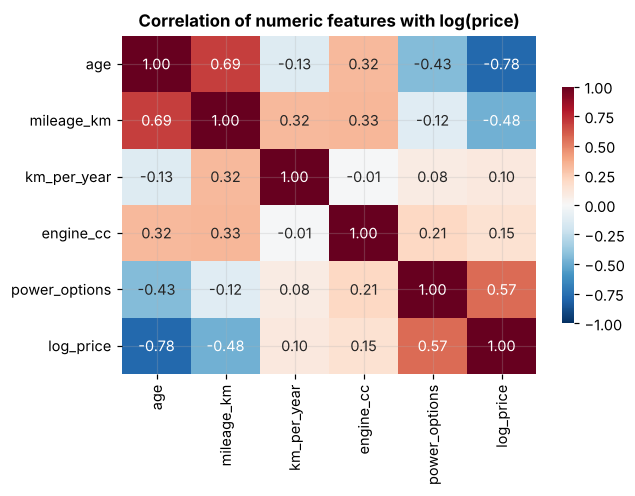

In [13]:
corr = data[NUM + ["price"]].assign(log_price=np.log(data["price"])).drop(columns="price").corr()
fig, ax = plt.subplots(figsize=(6, 4.6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": .7})
ax.set_title("Correlation of numeric features with log(price)")
savefig("04_correlation")

`power_options` correlates strongly with price (0.57), mostly because very old cars lack power
shutters or mirrors (it is −0.43 with age). Tree models cope with correlated inputs, but SHAP will
split credit between them, which I keep in mind when reading the explanations.

In [14]:
print("Missing values after cleaning (handled inside the model pipeline):")
print(data[FEATURES].isna().sum()[lambda s: s > 0])
print("\nListings by district (top 8):"); print(data["district"].value_counts().head(8))

Missing values after cleaning (handled inside the model pipeline):
mileage_km       3
km_per_year      3
engine_cc      193
dtype: int64

Listings by district (top 8):
district
Colombo       1922
Gampaha        964
Kurunegala     389
Kandy          314
Kalutara       273
Galle          172
Matara         167
Puttalam       121
Name: count, dtype: int64


## 4. Hold out unseen listings, then split train/test
I set aside **10 listings the model never sees** in training or
testing. They act as "new ads" for the inference demo and the Streamlit app. The rest is split 80/20
with a fixed seed.

In [15]:
new_listings = data.sample(10, random_state=7)
model_data = data.drop(new_listings.index)
X, y = model_data[FEATURES], model_data["price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(f"train {X_train.shape[0]:,} | test {X_test.shape[0]:,} | unseen new listings {len(new_listings)}")
new_listings[FEATURES + ["price"]].to_csv("data/new_listings_unseen.csv", index=False)
model_data.to_csv("data/clean_listings.csv", index=False)

train 3,921 | test 981 | unseen new listings 10


## 5. Preprocessing pipelines (leakage-safe)
All imputation, encoding and scaling sit **inside a scikit-learn `Pipeline`**. They are fitted only on
the training folds during cross-validation and never on test data, so there is no preprocessing leakage. The target is log-transformed with `TransformedTargetRegressor`, so every model
predicts in rupees.
* **Linear models:** median imputation, scaling, one-hot encoding.
* **Tree ensembles (RF / XGBoost / LightGBM):** median imputation, one-hot encoding (rare categories
  grouped). No scaling is needed for trees.
* **CatBoost:** reads the text categories directly using its ordered target statistics, and handles
  missing numbers itself.

In [16]:
def ohe(): return OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=5, sparse_output=False)

pre_linear = ColumnTransformer([("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM),
                                ("cat", ohe(), CAT)])
pre_tree = ColumnTransformer([("num", SimpleImputer(strategy="median"), NUM), ("cat", ohe(), CAT)])

def log_target(reg):
    return TransformedTargetRegressor(regressor=reg, func=np.log, inverse_func=np.exp)

def make_pipe(pre, est): return log_target(Pipeline([("pre", pre), ("model", est)]))

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

def evaluate(name, model, X_tr=X_train, y_tr=y_train):
    p_tr, p_te = model.predict(X_tr), model.predict(X_test)
    return {"Model": name,
            "Test MAE (Rs)": mean_absolute_error(y_test, p_te),
            "Test RMSE (Rs)": mean_squared_error(y_test, p_te) ** 0.5,
            "Test MAPE %": 100 * mean_absolute_percentage_error(y_test, p_te),
            "Test R²": r2_score(y_test, p_te),
            "Train R²": r2_score(y_tr, p_tr),
            "Within ±10% of price": np.mean(np.abs(p_te / y_test - 1) <= 0.10) * 100}
results, fitted, times = [], {}, {}

## 6. Baseline models (weak learners)
I start simple to see how far a weak learner gets before moving to ensembles.

In [17]:
t = time.time()
lin = make_pipe(pre_linear, LinearRegression()).fit(X_train, y_train)
fitted["Linear Regression"] = lin; results.append(evaluate("Linear Regression (baseline)", lin))
from sklearn.model_selection import cross_val_score
cv_mae = {"Linear Regression (baseline)": -cross_val_score(make_pipe(pre_linear, LinearRegression()), X_train, y_train,
                                                            cv=cv, scoring="neg_mean_absolute_error").mean()}

dt_search = GridSearchCV(make_pipe(pre_tree, DecisionTreeRegressor(random_state=SEED)),
                         {"regressor__model__max_depth": [6, 8, 10, 12, 15],
                          "regressor__model__min_samples_leaf": [2, 5, 10]},
                         cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1).fit(X_train, y_train)
fitted["Decision Tree"] = dt_search.best_estimator_
results.append(evaluate("Decision Tree (tuned)", dt_search.best_estimator_))
cv_mae["Decision Tree (tuned)"] = -dt_search.best_score_
print("Decision tree best:", dt_search.best_params_, f"({time.time()-t:.0f}s)")
pd.DataFrame(results).round(3)

Decision tree best: {'regressor__model__max_depth': 15, 'regressor__model__min_samples_leaf': 2} (9s)


,Model,Test MAE (Rs),Test RMSE (Rs),Test MAPE %,Test R²,Train R²,Within ±10% of price
0,Linear Regression (baseline),1028264.715,2075788.089,11.059,0.889,0.854,64.424
1,Decision Tree (tuned),932967.492,1972674.069,10.160,0.900,0.959,72.171


## 7. Ensemble models with hyper-parameter tuning
Each ensemble is tuned with `RandomizedSearchCV` (5-fold CV, scoring = mean absolute error on the
training set only). The search ranges below are my own choices, not library defaults.

| Model | Ensemble type | Key parameters searched |
|---|---|---|
| Random Forest | Bagging | `n_estimators`, `max_depth`, `min_samples_leaf`, `max_features` |
| XGBoost | Gradient boosting with L1/L2 regularisation | `n_estimators`, `learning_rate`, `max_depth`, `subsample`, `colsample_bytree`, `reg_lambda` |
| LightGBM | Leaf-wise gradient boosting | `n_estimators`, `learning_rate`, `num_leaves`, `min_child_samples`, `subsample` |
| CatBoost | Ordered boosting with native categoricals | `iterations`, `learning_rate`, `depth`, `l2_leaf_reg` |

In [18]:
BEST_PARAMS_FILE = "models/best_params.json"
best_params = json.load(open(BEST_PARAMS_FILE)) if (not TUNE and os.path.exists(BEST_PARAMS_FILE)) else {}
best_params = {k: v for k, v in best_params.items()}

def tune(name, pipe, space, n_iter):
    t = time.time()
    if TUNE:
        s = RandomizedSearchCV(pipe, space, n_iter=n_iter, cv=cv, scoring="neg_mean_absolute_error",
                               random_state=SEED, n_jobs=1).fit(X_train, y_train)
        best_params[name] = {k: (v.item() if hasattr(v, "item") else v) for k, v in s.best_params_.items()}
        model, cvm = s.best_estimator_, -s.best_score_
        best_params[name + "__cv_mae"] = float(cvm)
    else:
        model = pipe.set_params(**{k: v for k, v in best_params[name].items()}).fit(X_train, y_train); cvm = best_params.get(name + "__cv_mae", np.nan)
    cv_mae[f"{name} (tuned)"] = cvm
    times[name] = time.time() - t
    fitted[name] = model
    print(f"{name}: CV MAE Rs {cvm:,.0f} | {times[name]:.0f}s | {best_params[name]}")
    return model

rf = tune("Random Forest", make_pipe(pre_tree, RandomForestRegressor(random_state=SEED, n_jobs=-1)), {
    "regressor__model__n_estimators": [300, 500, 700],
    "regressor__model__max_depth": [None, 15, 25],
    "regressor__model__min_samples_leaf": [1, 2, 4],
    "regressor__model__max_features": [0.3, 0.5, 0.7]}, n_iter=10)
results.append(evaluate("Random Forest (tuned)", rf))

Random Forest: CV MAE Rs 836,410 | 137s | {'regressor__model__n_estimators': 500, 'regressor__model__min_samples_leaf': 1, 'regressor__model__max_features': 0.5, 'regressor__model__max_depth': None}


In [19]:
xgb = tune("XGBoost", make_pipe(pre_tree, XGBRegressor(random_state=SEED, n_jobs=-1, tree_method="hist")), {
    "regressor__model__n_estimators": [400, 700, 1000],
    "regressor__model__learning_rate": [0.02, 0.03, 0.05, 0.08],
    "regressor__model__max_depth": [4, 5, 6, 8],
    "regressor__model__subsample": [0.7, 0.85, 1.0],
    "regressor__model__colsample_bytree": [0.5, 0.7, 0.9],
    "regressor__model__min_child_weight": [1, 3, 5],
    "regressor__model__reg_lambda": [0.5, 1, 3, 5]}, n_iter=15)
results.append(evaluate("XGBoost (tuned)", xgb))

XGBoost: CV MAE Rs 844,885 | 75s | {'regressor__model__subsample': 0.85, 'regressor__model__reg_lambda': 0.5, 'regressor__model__n_estimators': 700, 'regressor__model__min_child_weight': 1, 'regressor__model__max_depth': 8, 'regressor__model__learning_rate': 0.03, 'regressor__model__colsample_bytree': 0.5}


In [20]:
lgbm = tune("LightGBM", make_pipe(pre_tree, LGBMRegressor(random_state=SEED, n_jobs=-1, verbose=-1)), {
    "regressor__model__n_estimators": [400, 700, 1000],
    "regressor__model__learning_rate": [0.02, 0.03, 0.05, 0.08],
    "regressor__model__num_leaves": [15, 31, 63],
    "regressor__model__min_child_samples": [5, 10, 20],
    "regressor__model__subsample": [0.7, 0.85, 1.0], "regressor__model__subsample_freq": [1],
    "regressor__model__colsample_bytree": [0.5, 0.7, 0.9],
    "regressor__model__reg_lambda": [0, 1, 5]}, n_iter=15)
results.append(evaluate("LightGBM (tuned)", lgbm))

LightGBM: CV MAE Rs 891,738 | 68s | {'regressor__model__subsample_freq': 1, 'regressor__model__subsample': 1.0, 'regressor__model__reg_lambda': 1, 'regressor__model__num_leaves': 63, 'regressor__model__n_estimators': 400, 'regressor__model__min_child_samples': 5, 'regressor__model__learning_rate': 0.03, 'regressor__model__colsample_bytree': 0.7}


In [21]:
from sklearn.preprocessing import FunctionTransformer
def fill_cats(X):
    X = X.copy(); X[CAT] = X[CAT].fillna("Unknown").astype(str); return X
pre_cat = FunctionTransformer(fill_cats)
cat_idx = tuple(FEATURES.index(c) for c in CAT)  # tuple so clone() works
cat = tune("CatBoost", make_pipe(pre_cat, CatBoostRegressor(cat_features=cat_idx, random_seed=SEED, verbose=0,
                                                           thread_count=-1, loss_function="RMSE")), {
    "regressor__model__iterations": [800, 1200],
    "regressor__model__learning_rate": [0.03, 0.05, 0.08],
    "regressor__model__depth": [6, 8],
    "regressor__model__l2_leaf_reg": [1, 3, 6]}, n_iter=8)
results.append(evaluate("CatBoost (tuned)", cat))

CatBoost: CV MAE Rs 868,811 | 373s | {'regressor__model__learning_rate': 0.08, 'regressor__model__l2_leaf_reg': 6, 'regressor__model__iterations': 1200, 'regressor__model__depth': 8}


### Stacking ensemble
Cross-validated stacking: the four tuned models are base learners. Their **out-of-fold**
predictions on log-price train a Ridge meta-learner, so the meta-learner never sees predictions a base
model made on its own training rows. That avoids stacking leakage.

In [22]:
t = time.time()
base = [(n.split()[0].lower(), fitted[n].regressor_ if hasattr(fitted[n], "regressor_") else fitted[n].regressor)
        for n in ["Random Forest", "XGBoost", "LightGBM", "CatBoost"]]
from sklearn.base import clone
stack = log_target(StackingRegressor(estimators=[(n, clone(p)) for n, p in base],
                                     final_estimator=RidgeCV(alphas=[0.1, 1, 10]), cv=5, n_jobs=1))
stack.fit(X_train, y_train)
fitted["Stacking"] = stack; times["Stacking"] = time.time() - t
results.append(evaluate("Stacking (RF+XGB+LGBM+Cat → Ridge)", stack))
print("Meta-learner weights:", dict(zip([n for n, _ in base], stack.regressor_.final_estimator_.coef_.round(3))),
      f"({times['Stacking']:.0f}s)")
json.dump(best_params, open(BEST_PARAMS_FILE, "w"), indent=2)

Meta-learner weights: {'random': np.float64(0.579), 'xgboost': np.float64(-0.063), 'lightgbm': np.float64(0.002), 'catboost': np.float64(0.492)} (116s)


## 8. Model comparison

In [23]:
res = pd.DataFrame(results).set_index("Model")
res.insert(0, "CV MAE (Rs, 5-fold train)", pd.Series(cv_mae))
res["Overfit gap (Train R² − Test R²)"] = res["Train R²"] - res["Test R²"]
show = res.copy()
for c in ["CV MAE (Rs, 5-fold train)", "Test MAE (Rs)", "Test RMSE (Rs)"]:
    show[c] = show[c].map(lambda v: "n/a" if pd.isna(v) else f"{v:,.0f}")
show.round(3)

,"CV MAE (Rs, 5-fold train)",Test MAE (Rs),Test RMSE (Rs),Test MAPE %,Test R²,Train R²,Within ±10% of price,Overfit gap (Train R² − Test R²)
Model,,,,,,,,
Linear Regression (baseline),"1,048,717","1,028,265","2,075,788",11.059,0.889,0.854,64.424,-0.035
Decision Tree (tuned),"1,050,182","932,967","1,972,674",10.160,0.900,0.959,72.171,0.059
Random Forest (tuned),"836,410","764,419","1,802,582",8.074,0.917,0.976,78.899,0.060
XGBoost (tuned),"844,885","782,595","1,743,671",8.520,0.922,0.992,77.370,0.071
LightGBM (tuned),"891,738","769,319","1,607,231",8.552,0.934,0.970,76.147,0.037
CatBoost (tuned),"868,811","824,434","1,831,461",8.882,0.914,0.936,74.720,0.022
Stacking (RF+XGB+LGBM+Cat → Ridge),n/a,"751,623","1,742,836",8.010,0.922,0.961,78.287,0.039


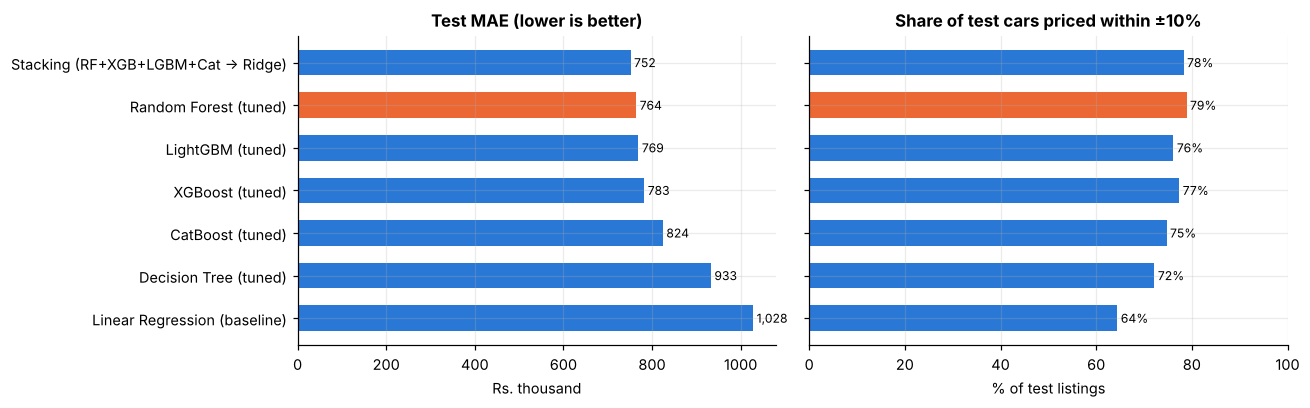

In [24]:
plot = res.sort_values("Test MAE (Rs)", ascending=False)
FINAL = "Random Forest (tuned)"
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
cols = [ORANGE if n == FINAL else BLUE for n in plot.index]
ax[0].barh(plot.index, plot["Test MAE (Rs)"] / 1e3, color=cols, height=0.6)
ax[0].set(title="Test MAE (lower is better)", xlabel="Rs. thousand")
for i, v in enumerate(plot["Test MAE (Rs)"] / 1e3): ax[0].text(v, i, f" {v:,.0f}", va="center", fontsize=8)
ax[1].barh(plot.index, plot["Within ±10% of price"], color=cols, height=0.6)
ax[1].set(title="Share of test cars priced within ±10%", xlabel="% of test listings", xlim=(0, 100))
for i, v in enumerate(plot["Within ±10% of price"]): ax[1].text(v, i, f" {v:.0f}%", va="center", fontsize=8)
ax[1].set_yticklabels([])
savefig("05_model_comparison")

### Choosing the final model
* Every ensemble clearly beats the weak learners. Linear regression misses by about 11% on average and
  the single decision tree by about 10%. The ensembles cut this to about 8–9%, as expected from
  bagging and boosting.
* **Stacking** has the lowest test MAE, but only about 2% better than Random Forest. The meta-learner
  puts nearly all its weight on RF and CatBoost (XGBoost and LightGBM add almost nothing), so stacking
  is essentially an RF + CatBoost blend that costs four models to train and explain.
* **Random Forest** has the **best 5-fold cross-validated MAE**, which is the most reliable estimate
  because it averages five splits rather than one. It is second on test MAE and prices the largest
  share of test cars within ±10%.
* LightGBM has the best R² / RMSE (fewer very large misses on luxury cars) but the worst CV MAE of
  the boosters, so its test result is partly luck of the split.

**Decision:** I deploy and explain the **tuned Random Forest**. It is a single model, so SHAP is
exact; it is the most consistent model on CV and test; and the ~2% accuracy given up versus stacking
is small compared with the gain in simplicity and explainability. Stacking is kept in the comparison
as the accuracy upper bound.

**Tuned RF parameters** (from the search): 500 trees, no depth limit, `min_samples_leaf=1`,
`max_features=0.5`. Each split looks at half the features, which de-correlates the trees (the main
variance-reduction idea of bagging).

In [25]:
final = fitted["Random Forest"]
rf_pipe = final.regressor_
pre_fit, rf_model = rf_pipe.named_steps["pre"], rf_pipe.named_steps["model"]
print({k.split("__")[-1]: v for k, v in rf_model.get_params().items()
       if k in ["n_estimators", "max_depth", "min_samples_leaf", "max_features"]})

{'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 1, 'n_estimators': 500}


### Overfitting check
* **Left: error by number of trees.** I refit the tuned RF on 85% of the training set and track RMSE on the other 15% as trees are
  added. The test set is not touched.
* **Right: learning curve.** Cross-validated error as the training set grows.

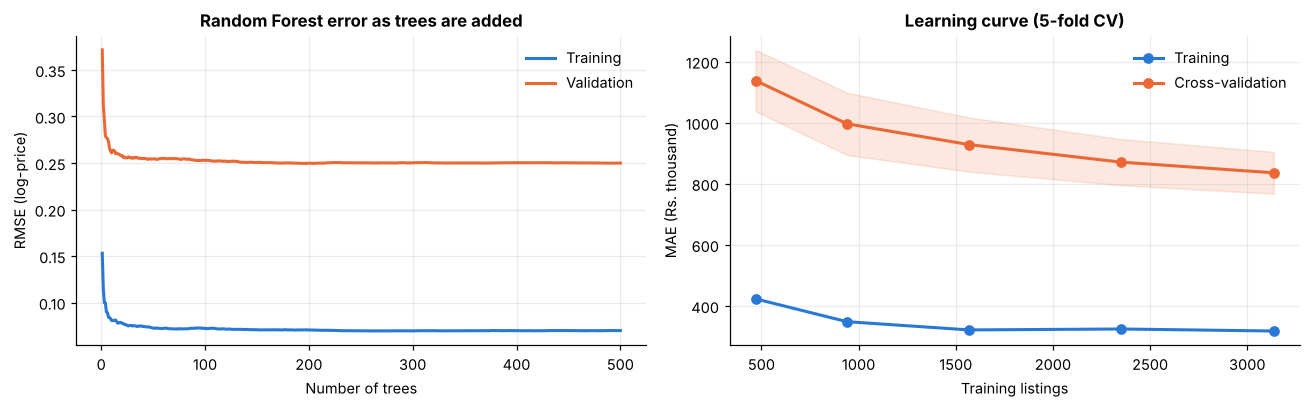

Validation RMSE after 50 trees 0.254, after 500 trees 0.250
CV MAE by training size: {np.int64(470): np.float64(1138000.0), np.int64(940): np.float64(996000.0), np.int64(1568): np.float64(928000.0), np.int64(2352): np.float64(871000.0), np.int64(3136): np.float64(836000.0)}


In [26]:
from sklearn.model_selection import learning_curve
Xa, Xv, ya, yv = train_test_split(X_train, np.log(y_train), test_size=0.15, random_state=SEED)
curve_rf = Pipeline([("pre", clone(pre_tree)), ("model", clone(rf_model))]).fit(Xa, ya)
Ta, Tv = curve_rf.named_steps["pre"].transform(Xa), curve_rf.named_steps["pre"].transform(Xv)
trees = curve_rf.named_steps["model"].estimators_
pa = np.cumsum([t.predict(Ta) for t in trees], axis=0) / np.arange(1, len(trees) + 1)[:, None]
pv = np.cumsum([t.predict(Tv) for t in trees], axis=0) / np.arange(1, len(trees) + 1)[:, None]
rmse_a = np.sqrt(((pa - ya.values) ** 2).mean(1)); rmse_v = np.sqrt(((pv - yv.values) ** 2).mean(1))

sizes, tr_sc, va_sc = learning_curve(clone(final), X_train, y_train, cv=cv, n_jobs=1,
                                     train_sizes=[0.15, 0.3, 0.5, 0.75, 1.0], scoring="neg_mean_absolute_error")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
n = np.arange(1, len(trees) + 1)
ax[0].plot(n, rmse_a, color=BLUE, lw=2, label="Training"); ax[0].plot(n, rmse_v, color=ORANGE, lw=2, label="Validation")
ax[0].set(title="Random Forest error as trees are added", xlabel="Number of trees", ylabel="RMSE (log-price)")
ax[0].legend(frameon=False)
ax[1].plot(sizes, -tr_sc.mean(1) / 1e3, "o-", color=BLUE, lw=2, label="Training")
ax[1].plot(sizes, -va_sc.mean(1) / 1e3, "o-", color=ORANGE, lw=2, label="Cross-validation")
ax[1].fill_between(sizes, (-va_sc.mean(1) - va_sc.std(1)) / 1e3, (-va_sc.mean(1) + va_sc.std(1)) / 1e3, color=ORANGE, alpha=0.15)
ax[1].set(title="Learning curve (5-fold CV)", xlabel="Training listings", ylabel="MAE (Rs. thousand)")
ax[1].legend(frameon=False); savefig("06_learning_curve")
print(f"Validation RMSE after 50 trees {rmse_v[49]:.3f}, after 500 trees {rmse_v[-1]:.3f}")
print("CV MAE by training size:", dict(zip(sizes, (-va_sc.mean(1)).round(-3))))

**Reading the overfitting check**
* **Trees (left):** validation error falls quickly and is flat after about 50 trees (RMSE 0.254 at 50
  trees, 0.250 at 500). It never turns upward, so adding trees does **not** overfit. That is a known
  property of bagging. The training error is lower because fully grown trees fit their own rows
  closely. What matters is that validation error is stable.
* **Data (right):** cross-validated MAE drops from about Rs 1.14M with 470 cars to Rs 0.84M with 3,136
  cars and is **still falling**. The model is limited by data more than by its settings, so collecting
  more listings is the most promising way to improve it.

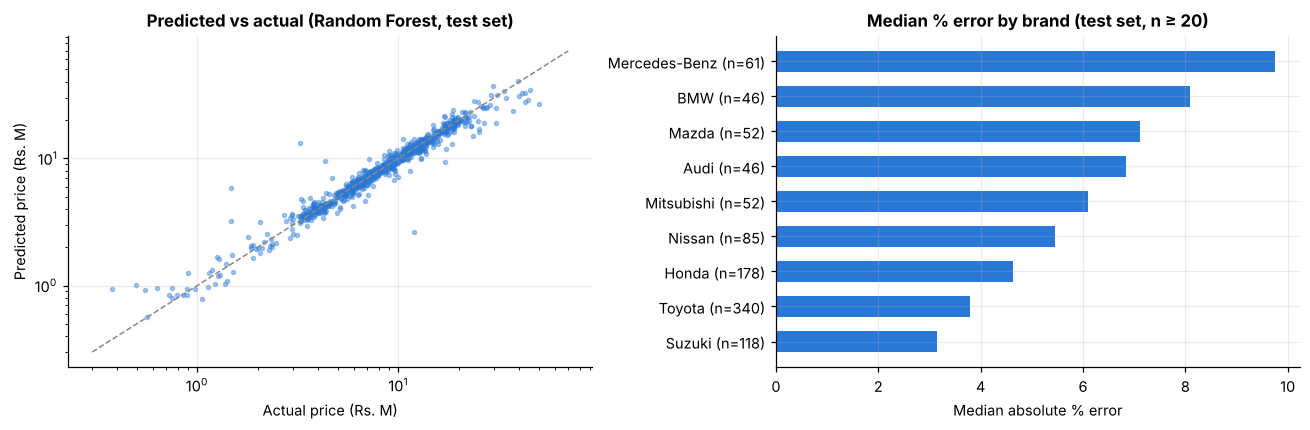

Median % error, cars ≤10 years old: 4.0 | >10 years: 5.1
Worst 5 test predictions:
         actual        pred       brand    model  age  abs_pct_err
184   3250000.0  13310000.0        Audi       A6   14   309.538146
2393  1475000.0   5829000.0      Nissan  Clipper    9   295.174526
2111   375000.0    939000.0  Mitsubishi   Lancer   46   150.483915
2056  4300000.0   9515000.0  Mitsubishi   Lancer   27   121.268742
2392  1475000.0   3200000.0      Nissan  Clipper   15   116.968145


In [27]:
pred = final.predict(X_test)
err = pd.DataFrame({"actual": y_test, "pred": pred, "brand": X_test["brand"], "model": X_test["model_family"], "age": X_test["age"]})
err["abs_pct_err"] = (err["pred"] / err["actual"] - 1).abs() * 100
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(err["actual"] / 1e6, err["pred"] / 1e6, s=7, alpha=0.4, color=BLUE)
lim = [0.3, 70]; ax[0].plot(lim, lim, color=GREY, lw=1, ls="--")
ax[0].set(xscale="log", yscale="log", title="Predicted vs actual (Random Forest, test set)",
          xlabel="Actual price (Rs. M)", ylabel="Predicted price (Rs. M)")
bb = err.groupby("brand").agg(med=("abs_pct_err", "median"), n=("abs_pct_err", "size"))
bb = bb[bb["n"] >= 20].sort_values("med")
ax[1].barh([f"{b} (n={k})" for b, k in zip(bb.index, bb["n"])], bb["med"], color=BLUE, height=0.6)
ax[1].set(title="Median % error by brand (test set, n ≥ 20)", xlabel="Median absolute % error")
savefig("07_errors")
print("Median % error, cars ≤10 years old:", round(err.loc[err.age <= 10, "abs_pct_err"].median(), 1),
      "| >10 years:", round(err.loc[err.age > 10, "abs_pct_err"].median(), 1))
print("Worst 5 test predictions:")
print(err.assign(actual=err.actual.round(-3), pred=err.pred.round(-3)).sort_values("abs_pct_err", ascending=False).head(5).to_string())

**Error analysis**
* The RF is a little more accurate for newer cars (median error 4.0% for cars up to 10 years old,
  5.1% for older ones). Older cars vary more in condition, which the ad does not capture.
* The biggest misses look like **data-quality problems, not model failures**. Examples: a 14-year-old
  Audi A6 advertised at Rs 3.25M (similar cars ask about Rs 13M, so probably a typo or a damaged car)
  and two identical Nissan Clipper ads at Rs 1.475M. Asking prices on classifieds are not verified.

## 9. Explainable AI: SHAP (global and local)
SHAP treats each feature as a "player" and fairly divides the prediction among them using
Shapley values. Two details for this model:
* The model predicts **log(price)**, so SHAP values are in log units. A SHAP value of +0.10 means the
  feature raises the price by about e^0.10 − 1 ≈ **+10.5%** compared with the average car (the
  *base value*).
* The RF sees one-hot columns (e.g. `brand_Toyota`, `brand_BMW`). SHAP values are additive, so I
  **sum the one-hot columns back into their original feature**. Each car then gets one readable value
  for `brand`, one for `district`, and so on.

Exact TreeSHAP on 500 deep trees takes about 1 s per car, so the global plots use a random sample of
300 test listings.

SHAP for 300 cars in 275s. Base value (average log-price) 15.867 → Rs 7,782,351
Additivity check (base + sum SHAP = model output): True


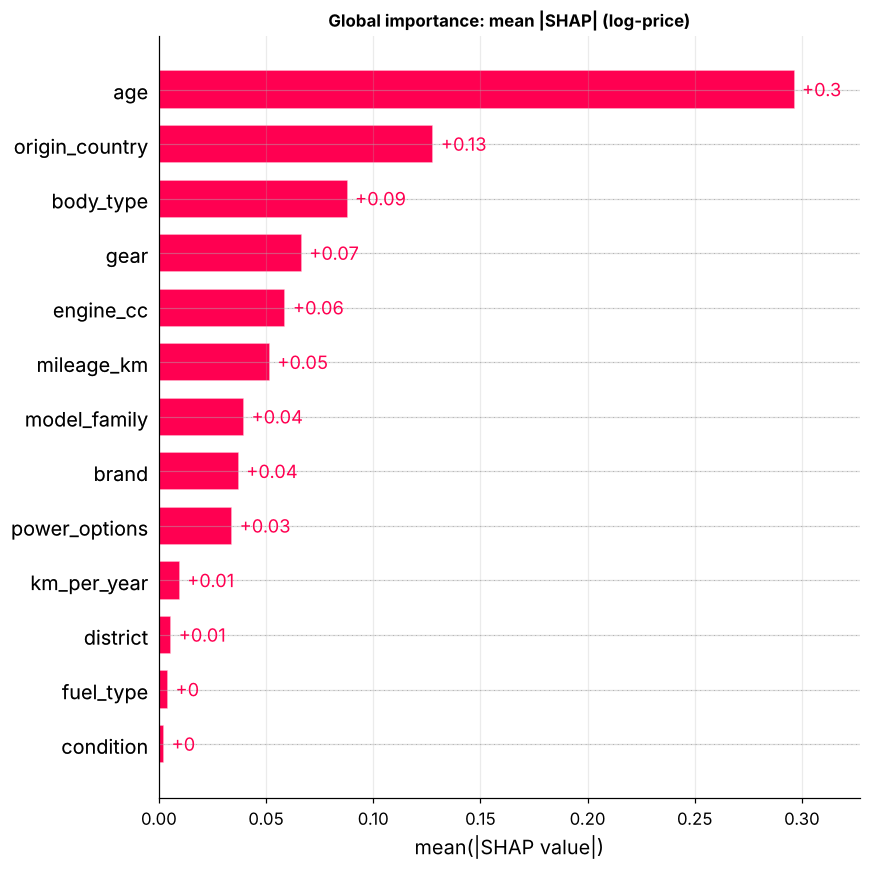

In [28]:
feat_names = pre_fit.get_feature_names_out()
def owner(n):
    kind, rest = n.split("__", 1)
    if kind == "num": return rest
    return next(c for c in sorted(CAT, key=len, reverse=True) if rest.startswith(c + "_"))
groups = np.array([owner(n) for n in feat_names])
tree_explainer = shap.TreeExplainer(rf_model)
BASE = float(np.ravel(tree_explainer.expected_value)[0])

def rf_shap(Xd):
    """SHAP values per ORIGINAL feature for the RF pipeline (one-hot columns summed)."""
    raw_sv = tree_explainer.shap_values(pre_fit.transform(Xd[FEATURES]))
    agg = pd.DataFrame(raw_sv, columns=groups).T.groupby(level=0).sum().T[FEATURES]
    color_data = Xd[FEATURES].copy()
    color_data[CAT] = np.nan
    return shap.Explanation(values=agg.values, base_values=np.full(len(Xd), BASE),
                            data=color_data.astype(float).values, display_data=Xd[FEATURES].values,
                            feature_names=FEATURES)

t = time.time()
X_shap = X_test.sample(300, random_state=SEED)
sv = rf_shap(X_shap)
print(f"SHAP for 300 cars in {time.time()-t:.0f}s. Base value (average log-price) {BASE:.3f} → Rs {np.exp(BASE):,.0f}")
print("Additivity check (base + sum SHAP = model output):",
      np.allclose(BASE + sv.values.sum(1), np.log(final.predict(X_shap)), atol=1e-4))
plt.figure(); shap.plots.bar(sv, max_display=13, show=False); plt.title("Global importance: mean |SHAP| (log-price)")
savefig("08_shap_bar")

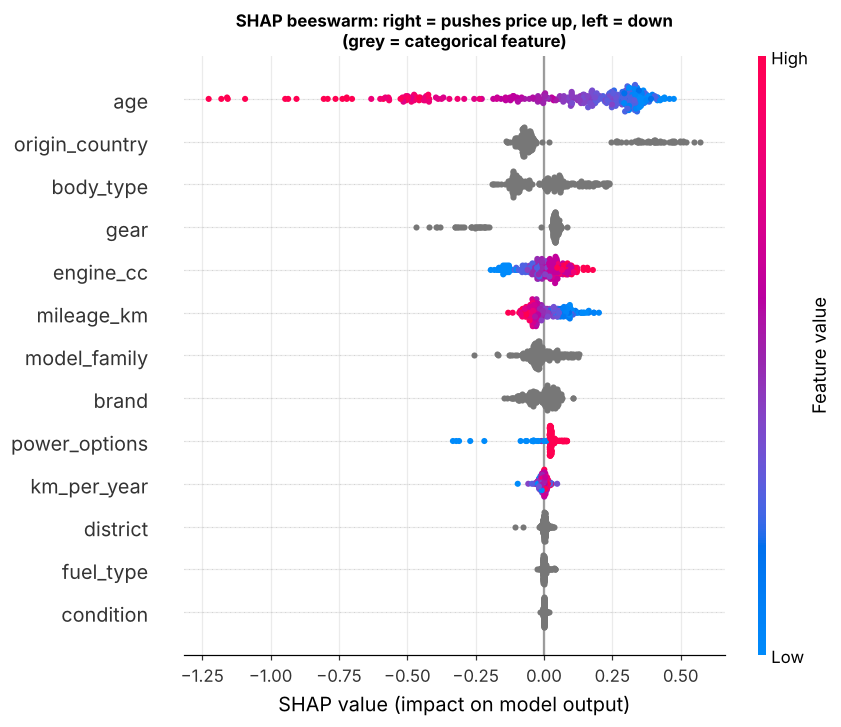

In [29]:
plt.figure(); shap.plots.beeswarm(sv, max_display=13, show=False)
plt.title("SHAP beeswarm: right = pushes price up, left = down\n(grey = categorical feature)")
savefig("09_shap_beeswarm")

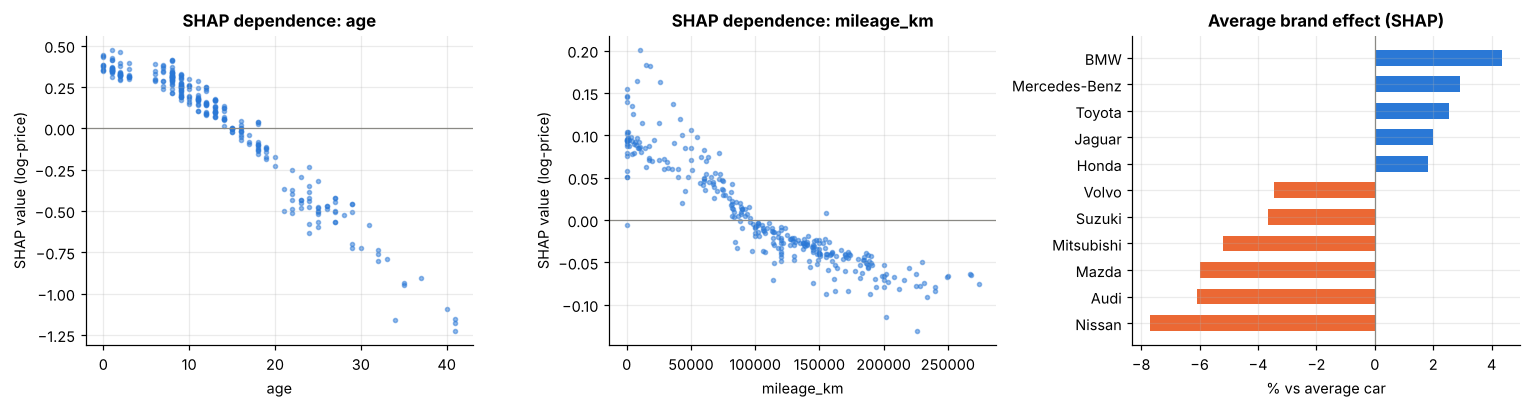

In [30]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, f in zip(ax[:2], ["age", "mileage_km"]):
    i = FEATURES.index(f)
    a.scatter(X_shap[f], sv.values[:, i], s=7, alpha=0.5, color=BLUE)
    a.axhline(0, color=GREY, lw=0.8)
    a.set(title=f"SHAP dependence: {f}", xlabel=f, ylabel="SHAP value (log-price)")
i = FEATURES.index("brand")
bs = pd.Series(sv.values[:, i], index=X_shap["brand"].values).groupby(level=0).mean().sort_values()
ax[2].barh(bs.index, (np.exp(bs.values) - 1) * 100, color=[BLUE if v > 0 else ORANGE for v in bs.values], height=0.6)
ax[2].axvline(0, color=GREY, lw=0.8); ax[2].set(title="Average brand effect (SHAP)", xlabel="% vs average car")
savefig("10_shap_dependence")

In [31]:
imp = pd.Series(np.abs(sv.values).mean(0), index=FEATURES).sort_values(ascending=False)
pd.DataFrame({"mean |SHAP|": imp.round(3), "≈ typical % effect on price": ((np.exp(imp) - 1) * 100).round(1)})

,mean |SHAP|,≈ typical % effect on price
age,0.297,34.5
origin_country,0.128,13.7
body_type,0.088,9.2
gear,0.067,6.9
engine_cc,0.059,6.1
mileage_km,0.052,5.3
model_family,0.040,4.1
brand,0.037,3.8
power_options,0.034,3.5
km_per_year,0.010,1.0


**Interpreting SHAP for the whole market**
* **Age dominates.** It moves a typical car's price by about 35%. In the beeswarm, high ages (red)
  sit far left (cheaper) and young cars (blue) sit right.
* **Origin is second.** The right-hand cluster for `origin_country` is the European (mostly German)
  cars, which carry a large premium (median Rs 16.8M vs Rs 7.7M for Japanese cars in the data).
* **Body type and gear:** SUVs push the price up. The separate left-hand cluster for `gear` is manual
  cars, which are mostly old models and cost much less.
* **Engine size and mileage** behave as expected: bigger engines (red) push the price up and high
  mileage (red) pulls it down.
* **Brand looks smaller than expected** because `origin_country` and `model_family` already carry most
  of the brand information. SHAP shares the credit among correlated features.
* **Location, fuel type and condition add under 1% each.** A car in Kandy is priced almost the same as
  one in Colombo. Fuel matters little once the model is known, since an Aqua or Prius is always a
  hybrid. These features could be dropped to simplify the model with almost no loss.

### Local explanation for one unseen listing (waterfall)
I pick an unseen listing of a common everyday model, the kind of car most buyers check.

      brand model_family  Model  year  mileage_km fuel_type          condition district       price
1032  Honda        Grace  Grace  2016    118000.0    Hybrid  Registered (Used)    Kandy  10500000.0
Predicted: Rs 9,753,431  |  Actual asking price: Rs 10,500,000


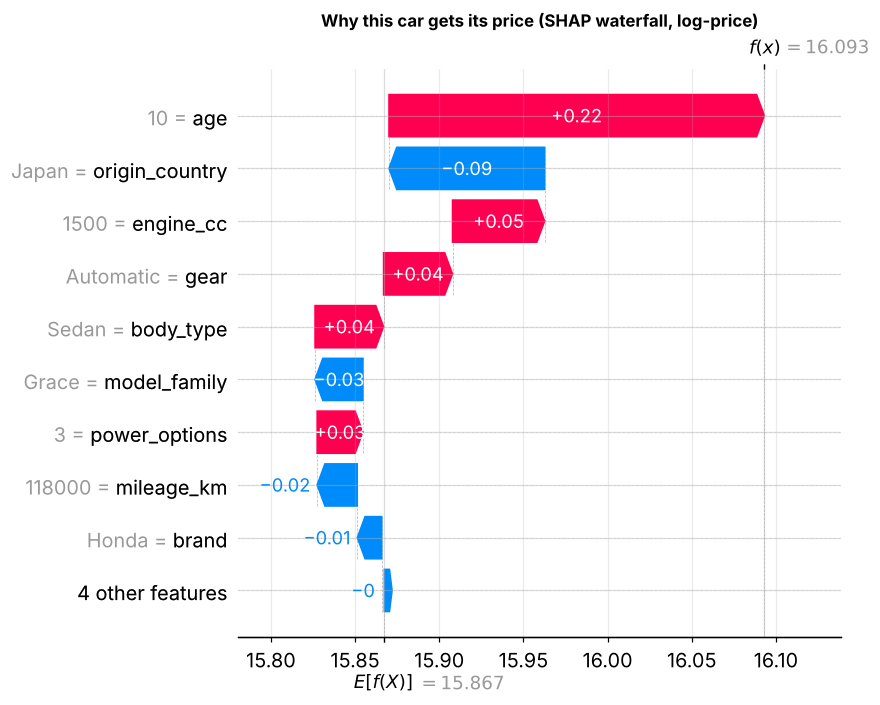

,value,SHAP,≈ % effect
origin_country,Japan,-0.092,-8.8
model_family,Grace,-0.028,-2.8
mileage_km,118000.0,-0.024,-2.4
brand,Honda,-0.015,-1.4
fuel_type,Hybrid,-0.004,-0.4
condition,Registered (Used),-0.001,-0.1
km_per_year,11800.0,0.002,0.2
district,Kandy,0.002,0.2
power_options,3,0.027,2.8
gear,Automatic,0.041,4.2


In [32]:
everyday = ["Aqua", "Vitz", "Premio", "Allion", "Fit", "Prius", "Wagon R", "Axio", "Grace", "Yaris"]
cands = new_listings[new_listings["model_family"].isin(everyday)]
case = (cands if len(cands) else new_listings).iloc[[0]]
case_sv = rf_shap(case)
print(case[["brand", "model_family", "Model", "year", "mileage_km", "fuel_type", "condition", "district", "price"]].to_string())
case_pred = final.predict(case[FEATURES])[0]
print(f"Predicted: Rs {case_pred:,.0f}  |  Actual asking price: Rs {case['price'].iloc[0]:,.0f}")
plt.figure(); shap.plots.waterfall(case_sv[0], max_display=10, show=False)
plt.title("Why this car gets its price (SHAP waterfall, log-price)"); savefig("11_shap_waterfall")
pd.DataFrame({"value": case[FEATURES].iloc[0].values, "SHAP": case_sv.values[0].round(3),
              "≈ % effect": ((np.exp(case_sv.values[0]) - 1) * 100).round(1)}, index=FEATURES).sort_values("SHAP")

**Reading the waterfall.** The RF starts from the average listing, log-price 15.87 or Rs 7.78M. For
this 2016 Honda Grace hybrid in Kandy:
* **Age 10** is younger than the average car in the data (about 14 years), worth about **+25%**.
* **Japanese origin** is about −9%, because the average includes expensive European cars.
* **1,500 cc engine, automatic and sedan body** add about +4–6% each.
* **118,000 km** and the **Grace model** take off about 2–3% each.

The result is **Rs 9.75M** against an asking price of Rs 10.5M. The seller is about 7.7% above the
estimate, which is inside the model's typical error (~8%), so: **fair, slightly on the high side**.

## 10. Explainable AI: LIME (local surrogate)
LIME perturbs the chosen listing to create synthetic neighbours, asks the black-box RF to
price them, weights each neighbour by its closeness (proximity kernel), and fits a weighted linear model.
Categories are label-encoded only for LIME's sampler and decoded back before every prediction.

**Known limitation:** LIME samples features independently, so some neighbours are
unrealistic (a 2-year-old car with 300,000 km, a Wagon R with a German origin). Its local R² tells us
how well the straight-line surrogate fits. A low value means "read the weights as direction, not exact
size".

LIME local surrogate R² = 0.19 | surrogate prediction Rs 9,564,771 vs RF Rs 9,753,431


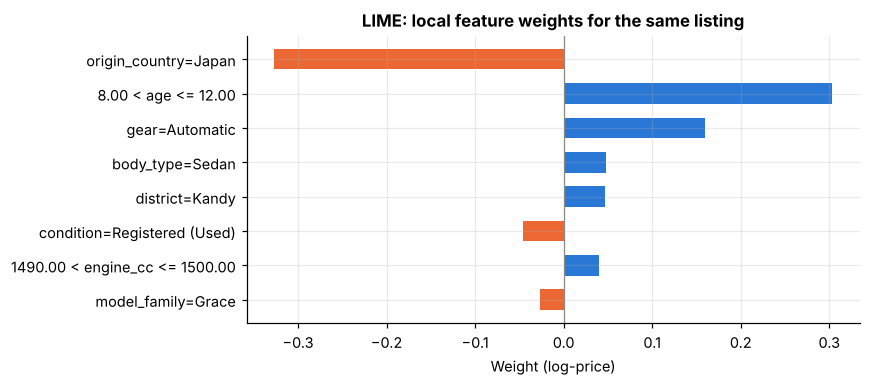

,Condition (LIME),Weight (log-price),≈ % effect
0,origin_country=Japan,-0.326669,-27.9
1,8.00 < age <= 12.00,0.302797,35.4
2,gear=Automatic,0.159345,17.3
3,body_type=Sedan,0.047932,4.9
4,district=Kandy,0.046256,4.7
5,condition=Registered (Used),-0.045936,-4.5
6,1490.00 < engine_cc <= 1500.00,0.040053,4.1
7,model_family=Grace,-0.026664,-2.6


In [33]:
cat_maps = {c: sorted(X_train[c].unique()) for c in CAT}
num_median = X_train[NUM].median()
def encode(Xd):
    Z = Xd[FEATURES].copy()
    for c in CAT: Z[c] = Z[c].map({v: i for i, v in enumerate(cat_maps[c])}).fillna(0)
    for c in NUM: Z[c] = Z[c].fillna(num_median[c])
    return Z.astype(float)
def decode(Z):
    D = pd.DataFrame(Z, columns=FEATURES)
    for c in CAT: D[c] = [cat_maps[c][int(round(v))] for v in D[c]]
    for c in NUM: D[c] = D[c].astype(float)
    return D
lime_exp = LimeTabularExplainer(encode(X_train).values, feature_names=FEATURES, mode="regression",
                                categorical_features=[FEATURES.index(c) for c in CAT],
                                categorical_names={FEATURES.index(c): cat_maps[c] for c in CAT},
                                discretize_continuous=True, random_state=SEED)
predict_log = lambda Z: np.log(final.predict(decode(Z)))
exp = lime_exp.explain_instance(encode(case).values[0], predict_log, num_features=8, num_samples=2000)
w = pd.DataFrame(exp.as_list(), columns=["Condition (LIME)", "Weight (log-price)"])
w["≈ % effect"] = ((np.exp(w["Weight (log-price)"]) - 1) * 100).round(1)
print(f"LIME local surrogate R² = {exp.score:.2f} | surrogate prediction Rs {np.exp(exp.local_pred[0]):,.0f} "
      f"vs RF Rs {case_pred:,.0f}")
fig, ax = plt.subplots(figsize=(8, 3.6))
wp = w.iloc[::-1]
ax.barh(wp["Condition (LIME)"], wp["Weight (log-price)"], color=[BLUE if v > 0 else ORANGE for v in wp["Weight (log-price)"]], height=0.6)
ax.axvline(0, color=GREY, lw=0.8); ax.set(title="LIME: local feature weights for the same listing", xlabel="Weight (log-price)")
savefig("12_lime")
w

**SHAP vs LIME on the same car.** LIME agrees on the *direction* of the important features: age
(8–12 years) up, Japanese origin down, automatic up, Grace down. The *sizes* differ a lot, though
(Japan −28% in LIME vs −9% in SHAP), and LIME's local R² is only about 0.2. The straight-line
surrogate does not fit the RF well around this car, because the RF is highly non-linear and many of
LIME's synthetic neighbours are unrealistic. **Conclusion:** I use SHAP, which is exact for tree
models, as the main explanation and LIME only as a check on direction.

## 11. What-if analysis (counterfactual style)
For a buyer or seller the useful question is *"what would change this price?"* I keep the same listing,
change one feature at a time, and hold the rest fixed. This is a simple, readable counterfactual.

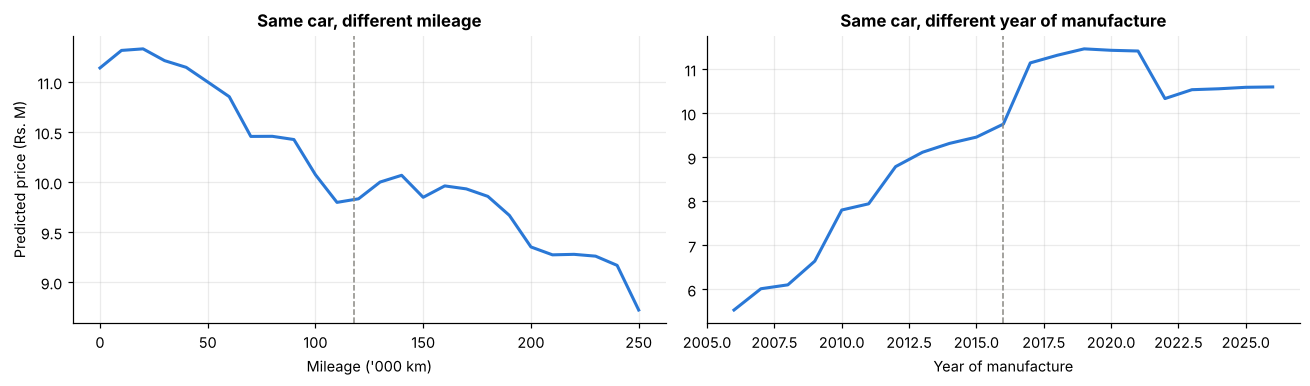

At year 2016: 50,000 km → Rs 11,001,620; 150,000 km → Rs 9,849,147 (-10.5%)


In [34]:
base_row = case[FEATURES].copy()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
km = np.linspace(0, 250_000, 26); rows = pd.concat([base_row] * len(km)); rows["mileage_km"] = km
rows["km_per_year"] = km / max(base_row["age"].iloc[0], 1)
ax[0].plot(km / 1000, final.predict(rows) / 1e6, color=BLUE, lw=2)
ax[0].axvline(base_row["mileage_km"].iloc[0] / 1000, color=GREY, ls="--", lw=1)
ax[0].set(title="Same car, different mileage", xlabel="Mileage ('000 km)", ylabel="Predicted price (Rs. M)")
ages = np.arange(0, 21); rows = pd.concat([base_row] * len(ages)); rows["age"] = ages
rows["km_per_year"] = base_row["mileage_km"].iloc[0] / np.maximum(ages, 1)
ax[1].plot(REF_YEAR - ages, final.predict(rows) / 1e6, color=BLUE, lw=2)
ax[1].axvline(REF_YEAR - base_row["age"].iloc[0], color=GREY, ls="--", lw=1)
ax[1].set(title="Same car, different year of manufacture", xlabel="Year of manufacture")
savefig("13_what_if")
m_lo, m_hi = final.predict(rows.assign(mileage_km=50_000, km_per_year=50_000 / np.maximum(rows.age, 1)).iloc[[10]])[0], \
             final.predict(rows.assign(mileage_km=150_000, km_per_year=150_000 / np.maximum(rows.age, 1)).iloc[[10]])[0]
print(f"At year {REF_YEAR-10}: 50,000 km → Rs {m_lo:,.0f}; 150,000 km → Rs {m_hi:,.0f} ({(m_hi/m_lo-1)*100:+.1f}%)")

**What-if reading.** With everything else fixed, a 2016 car with 150,000 km is worth about **10.5%
less** than the same car with 50,000 km. On the year curve, each newer year adds value, and the
steepest rise is for the newest cars. The curves move in steps because a Random Forest makes
piecewise-constant predictions. Sellers can use this directly: for example, how much is low mileage
worth?

## 12. Inference on the 10 unseen listings
These ads were removed before the train/test split. The model has never seen them.

In [35]:
inf = new_listings.copy()
inf["Predicted (Rs)"] = final.predict(inf[FEATURES]).round(-4)
inf["Error %"] = ((inf["Predicted (Rs)"] / inf["price"] - 1) * 100).round(1)
inf["Verdict on asking price"] = np.select([inf["Error %"] > 10, inf["Error %"] < -10], ["Looks LOW (bargain?)", "Looks HIGH"], "Fair")
out = inf[["brand", "model_family", "year", "mileage_km", "fuel_type", "district", "price", "Predicted (Rs)", "Error %", "Verdict on asking price"]]
print("Median absolute error on unseen listings:", f"{inf['Error %'].abs().median():.1f}%")
out.rename(columns={"price": "Asking (Rs)"}).style.format({"Asking (Rs)": "{:,.0f}", "Predicted (Rs)": "{:,.0f}", "mileage_km": "{:,.0f}", "Error %": "{:+.1f}"})

Median absolute error on unseen listings: 8.4%


,brand,model_family,year,mileage_km,fuel_type,district,Asking (Rs),Predicted (Rs),Error %,Verdict on asking price
1121,Honda,Vezel,2025,"5,000",Petrol,Badulla,"17,500,000","19,510,000",+11.5,Looks LOW (bargain?)
387,BMW,3 Series,2002,"207,000",Petrol,Colombo,"6,450,000","6,260,000",-2.9,Fair
1032,Honda,Grace,2016,"118,000",Hybrid,Kandy,"10,500,000","9,750,000",-7.1,Fair
2779,Suzuki,Swift,2008,"151,000",Petrol,Kalutara,"4,750,000","5,330,000",+12.2,Looks LOW (bargain?)
3212,Toyota,Allion,2007,"248,000",Petrol,Kandy,"8,650,000","8,460,000",-2.2,Fair
4188,Toyota,Prius,2013,"212,000",Hybrid,Colombo,"11,200,000","9,770,000",-12.8,Looks HIGH
1812,Mercedes-Benz,S-Class,2014,"42,000",Hybrid,Colombo,"35,000,000","34,730,000",-0.8,Fair
4314,Toyota,Raize,2025,"21,000",Petrol,Ratnapura,"13,690,000","12,100,000",-11.6,Looks HIGH
4296,Toyota,Raize,2023,"6,000",Petrol,Colombo,"12,590,000","13,200,000",+4.8,Fair
4775,Toyota,Yaris,2017,"151,440",Petrol,Colombo,"9,500,000","8,570,000",-9.8,Fair


The median error on the 10 hidden ads (about 8%) matches the test-set MAPE (8.1%). The model
**generalises to new listings** and was not tuned to the test split by accident.

## 13. Save the model for the Streamlit app
The whole pipeline (preprocessing, Random Forest and log-target) is saved with joblib, together with
the dropdown options the app needs.

In [36]:
brand_models = {b: sorted(data.loc[data["brand"] == b, "model_family"].unique()) for b in sorted(data["brand"].unique())}
model_defaults = (data.groupby("model_family").agg(engine_cc=("engine_cc", "median"),
                  body_type=("body_type", lambda s: s.mode()[0]), fuel_type=("fuel_type", lambda s: s.mode()[0]),
                  origin_country=("origin_country", lambda s: s.mode()[0])).to_dict("index"))
bundle = {"model": final, "model_name": "Random Forest (tuned)", "features": FEATURES, "cat": CAT, "num": NUM,
          "ref_year": REF_YEAR, "brand_models": brand_models, "model_defaults": model_defaults,
          "options": {c: sorted(data[c].unique()) for c in CAT},
          "test_mae": float(res.loc[FINAL, "Test MAE (Rs)"]), "test_mape": float(res.loc[FINAL, "Test MAPE %"]),
          "trained_on": int(len(X_train)), "data_period": f"{data['ad_date'].min():%b %Y} – {data['ad_date'].max():%b %Y}"}
joblib.dump(bundle, "models/vehicle_price_model.joblib", compress=3)
res.to_csv("models/model_comparison.csv")
summary = {"n_raw": int(len(raw)), "n_clean": int(len(data)), "n_train": int(len(X_train)), "n_test": int(len(X_test)),
           "period": bundle["data_period"], "cleaning_log": log, "shap_importance": imp.round(4).to_dict(),
           "base_price": float(np.exp(BASE)), "case": {"desc": f"{case['year'].iloc[0]} {case['brand'].iloc[0]} {case['model_family'].iloc[0]}",
           "mileage": float(case['mileage_km'].iloc[0]), "district": case['district'].iloc[0], "asking": float(case['price'].iloc[0]),
           "pred": float(case_pred), "lime_r2": float(exp.score)}, "rf_curve": {"train": rmse_a[::10].round(4).tolist(),
           "val": rmse_v[::10].round(4).tolist()}, "unseen_median_err": float(inf['Error %'].abs().median()),
           "stack_weights": dict(zip([n for n, _ in base], stack.regressor_.final_estimator_.coef_.round(3).tolist())),
           "year_counts": data["year"].value_counts().sort_index().to_dict()}
json.dump(summary, open("models/summary.json", "w"), indent=2, default=str)
print("Saved models/vehicle_price_model.joblib", f"{os.path.getsize('models/vehicle_price_model.joblib')/1e6:.1f} MB")

Saved models/vehicle_price_model.joblib 40.1 MB


## 14. Conclusions and limitations
**Conclusions**
1. Real, messy Sri Lankan listings can be priced to about **8% typical error** with a tuned Random
   Forest (test MAE ≈ Rs 0.76M, R² 0.92). That beats a linear-regression baseline (11%) and a single
   tree (10%).
2. Ensembles clearly beat weak learners, but among ensembles the differences are small (about 8–9%).
   Stacking gave the lowest test MAE, but I chose the simpler, more consistent RF for deployment.
3. SHAP shows the price is mostly **age, origin (European premium), body type and transmission**.
   Location, fuel type and condition hardly matter once the model is known.

**Limitations**
* These are **asking prices**, not sale prices. Sellers' expectations are not market clearing prices.
* 22% of ads ("Negotiable") have no price and are excluded. If they differ systematically (e.g. more
  luxury cars), the model is biased towards the priced segment.
* About three months of data (May–Aug 2026) from one website, in a market still adjusting after the
  2025 reopening. The model will **drift** and must be retrained.
* Car condition, accident history and number of owners are not in the ads, and they explain part of
  the remaining error.
* LIME's independent sampling creates unrealistic neighbours, so its weights are approximate.
